# ACO: five-city tour from your notes
Find a short tour through **A, B, C, D, E**, visiting every city once and returning to the start. Distances are symmetric.

We reproduce **one complete iteration**, with three ants starting from A, B, and C and using the tours written in the notes. Probabilities are computed accurately rather than copying the rounded arithmetic errors.

Run the cells in order. Only NumPy and Matplotlib are required.

## 1. Import the libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 2. Enter the distance matrix
The diagonal is zero because a city has no distance to itself.

In [2]:
cities = np.array(["A", "B", "C", "D", "E"])
distance = np.array([
    [0, 2, 9, 10, 7],
    [2, 0, 6, 4, 3],
    [9, 6, 0, 8, 9],
    [10, 4, 8, 0, 5],
    [7, 3, 9, 5, 0]
], dtype=float)

def show_matrix(matrix, title):
    print(title)
    print("      " + "".join(f"{city:>9}" for city in cities))
    for city, row in zip(cities, matrix):
        print(f"{city:>5} " + "".join(f"{value:9.4f}" for value in row))

show_matrix(distance, "Distances")

Distances
              A        B        C        D        E
    A    0.0000   2.0000   9.0000  10.0000   7.0000
    B    2.0000   0.0000   6.0000   4.0000   3.0000
    C    9.0000   6.0000   0.0000   8.0000   9.0000
    D   10.0000   4.0000   8.0000   0.0000   5.0000
    E    7.0000   3.0000   9.0000   5.0000   0.0000


## 3. Set the parameters from the notes
α controls pheromone influence, β controls distance preference, ρ is evaporation, and Q scales the deposit.

In [3]:
alpha = 1
beta = 2
rho = 0.5
Q = 100
start_cities = [0, 1, 2]
pheromone = np.ones_like(distance)
np.fill_diagonal(pheromone, 0)
show_matrix(pheromone, "Initial pheromone")

Initial pheromone
              A        B        C        D        E
    A    0.0000   1.0000   1.0000   1.0000   1.0000
    B    1.0000   0.0000   1.0000   1.0000   1.0000
    C    1.0000   1.0000   0.0000   1.0000   1.0000
    D    1.0000   1.0000   1.0000   0.0000   1.0000
    E    1.0000   1.0000   1.0000   1.0000   0.0000


## 4. Calculate desirability
$$\eta_{ij}=1/d_{ij}$$
Shorter edges have greater desirability. Set the diagonal to zero to avoid dividing by zero.

In [4]:
eta = np.zeros_like(distance)
np.divide(1.0, distance, out=eta, where=distance > 0)
show_matrix(eta, "Desirability: eta")
show_matrix(eta**beta, "Squared desirability: eta^2")

Desirability: eta
              A        B        C        D        E
    A    0.0000   0.5000   0.1111   0.1000   0.1429
    B    0.5000   0.0000   0.1667   0.2500   0.3333
    C    0.1111   0.1667   0.0000   0.1250   0.1111
    D    0.1000   0.2500   0.1250   0.0000   0.2000
    E    0.1429   0.3333   0.1111   0.2000   0.0000
Squared desirability: eta^2
              A        B        C        D        E
    A    0.0000   0.2500   0.0123   0.0100   0.0204
    B    0.2500   0.0000   0.0278   0.0625   0.1111
    C    0.0123   0.0278   0.0000   0.0156   0.0123
    D    0.0100   0.0625   0.0156   0.0000   0.0400
    E    0.0204   0.1111   0.0123   0.0400   0.0000


## 5. Calculate transition probabilities
An ant can move only to an unvisited city.
$$p_{ij}=\frac{\tau_{ij}^{\alpha}\eta_{ij}^{\beta}}{\sum_{h\in\mathrm{unvisited}}\tau_{ih}^{\alpha}\eta_{ih}^{\beta}}$$
The denominator changes after each move. Returning to the starting city happens only after all cities have been visited.

In [5]:
def transition_probabilities(current, unvisited, pheromone):
    weights = pheromone[current, unvisited]**alpha * eta[current, unvisited]**beta
    return weights / weights.sum()

def show_choices(current, unvisited, pheromone):
    weights = pheromone[current, unvisited]**alpha * eta[current, unvisited]**beta
    probabilities = transition_probabilities(current, unvisited, pheromone)
    print(f"From {cities[current]} | denominator = {weights.sum():.6f}")
    for target, weight, probability in zip(unvisited, weights, probabilities):
        print(f"  {cities[current]} → {cities[target]}: weight = {weight:.6f}, p = {probability:.6f}")
    return probabilities

## 6. First move of the ant starting at A
All pheromones are 1, so the weights are simply 1 / distance².

**Arithmetic correction:** the A–D weight is 1/10² = **0.01**, giving a total of about **0.292754**. Thus P(A→B) is about **0.85396**.

In [6]:
probabilities_A = show_choices(0, [1, 2, 3, 4], pheromone)

From A | denominator = 0.292754
  A → B: weight = 0.250000, p = 0.853960
  A → C: weight = 0.012346, p = 0.042171
  A → D: weight = 0.010000, p = 0.034158
  A → E: weight = 0.020408, p = 0.069711


## 7. First move of the ant starting at B

In [7]:
probabilities_B = show_choices(1, [0, 2, 3, 4], pheromone)

From B | denominator = 0.451389
  B → A: weight = 0.250000, p = 0.553846
  B → C: weight = 0.027778, p = 0.061538
  B → D: weight = 0.062500, p = 0.138462
  B → E: weight = 0.111111, p = 0.246154


## 8. First move of the ant starting at C
Use the same formula; the precise values differ slightly from the rounded values in the notes.

In [8]:
probabilities_C = show_choices(2, [0, 1, 3, 4], pheromone)

From C | denominator = 0.068094
  C → A: weight = 0.012346, p = 0.181303
  C → B: weight = 0.027778, p = 0.407932
  C → D: weight = 0.015625, p = 0.229462
  C → E: weight = 0.012346, p = 0.181303


## 9. Enter the three tours shown in the notes
These are **given sampled tours**, entered explicitly to reproduce the worked example. A general ACO program samples each next city using the transition probabilities; choosing the largest probability every time would be a different rule.

In [9]:
tours = [
    [0, 1, 4, 3, 2, 0],
    [1, 0, 4, 3, 2, 1],
    [2, 1, 0, 4, 3, 2]
]

for ant, tour in enumerate(tours, start=1):
    print(f"Ant {ant}: " + " → ".join(cities[tour]))

Ant 1: A → B → E → D → C → A
Ant 2: B → A → E → D → C → B
Ant 3: C → B → A → E → D → C


## 10. Follow every move step by step
Recalculate probabilities using only the remaining cities. All three ants use the initial pheromone; updates happen after all tours are complete.

In [10]:
for ant, tour in enumerate(tours, start=1):
    print(f"\nANT {ant}")
    visited = {tour[0]}
    for current, next_city in zip(tour[:-2], tour[1:-1]):
        unvisited = [i for i in range(len(cities)) if i not in visited]
        show_choices(current, unvisited, pheromone)
        print(f"  Given move: {cities[current]} → {cities[next_city]}")
        visited.add(next_city)
    print(f"Return: {cities[tour[-2]]} → {cities[tour[-1]]}")


ANT 1
From A | denominator = 0.292754
  A → B: weight = 0.250000, p = 0.853960
  A → C: weight = 0.012346, p = 0.042171
  A → D: weight = 0.010000, p = 0.034158
  A → E: weight = 0.020408, p = 0.069711
  Given move: A → B
From B | denominator = 0.201389
  B → C: weight = 0.027778, p = 0.137931
  B → D: weight = 0.062500, p = 0.310345
  B → E: weight = 0.111111, p = 0.551724
  Given move: B → E
From E | denominator = 0.052346
  E → C: weight = 0.012346, p = 0.235849
  E → D: weight = 0.040000, p = 0.764151
  Given move: E → D
From D | denominator = 0.015625
  D → C: weight = 0.015625, p = 1.000000
  Given move: D → C
Return: C → A

ANT 2
From B | denominator = 0.451389
  B → A: weight = 0.250000, p = 0.553846
  B → C: weight = 0.027778, p = 0.061538
  B → D: weight = 0.062500, p = 0.138462
  B → E: weight = 0.111111, p = 0.246154
  Given move: B → A
From A | denominator = 0.042754
  A → C: weight = 0.012346, p = 0.288762
  A → D: weight = 0.010000, p = 0.233897
  A → E: weight = 0.0204

## 11. Calculate each tour length
$$L_k=\sum_{(i,j)\in\mathrm{tour}_k}d_{ij}$$
Include the final edge back to the start.

In [11]:
lengths = []
for ant, tour in enumerate(tours, start=1):
    edge_lengths = distance[tour[:-1], tour[1:]]
    length = edge_lengths.sum()
    lengths.append(length)
    calculation = " + ".join(f"{value:g}" for value in edge_lengths)
    print(f"Ant {ant}: {calculation} = {length:g}")
lengths = np.array(lengths)

Ant 1: 2 + 3 + 5 + 8 + 9 = 27
Ant 2: 2 + 7 + 5 + 8 + 6 = 28
Ant 3: 6 + 2 + 7 + 5 + 8 = 28


## 12. Calculate each ant's pheromone reward
$$\Delta\tau_{ij}^{(k)}=\begin{cases}Q/L_k & \text{if ant }k\text{ uses edge }(i,j)\\0 & \text{otherwise}\end{cases}$$
An ant deposits this amount on **each edge it used**, including its return edge. Shorter tours earn larger deposits.

In [12]:
rewards = Q / lengths
for ant, (length, reward) in enumerate(zip(lengths, rewards), start=1):
    print(f"Ant {ant}: Q/L = {Q}/{length:g} = {reward:.6f}")

Ant 1: Q/L = 100/27 = 3.703704
Ant 2: Q/L = 100/28 = 3.571429
Ant 3: Q/L = 100/28 = 3.571429


## 13. Add deposits from all ants
$$\Delta\tau_{ij}=\sum_k\Delta\tau_{ij}^{(k)}$$
Because distances are symmetric, an edge receives the same deposit in both directions. Edges unused by every ant receive zero.

In [13]:
deposits = np.zeros_like(distance)
for tour, reward in zip(tours, rewards):
    for i, j in zip(tour[:-1], tour[1:]):
        deposits[i, j] += reward
        deposits[j, i] += reward

show_matrix(deposits, "Total deposit on every edge")

Total deposit on every edge
              A        B        C        D        E
    A    0.0000  10.8466   3.7037   0.0000   7.1429
    B   10.8466   0.0000   7.1429   0.0000   3.7037
    C    3.7037   7.1429   0.0000  10.8466   0.0000
    D    0.0000   0.0000  10.8466   0.0000  10.8466
    E    7.1429   3.7037   0.0000  10.8466   0.0000


## 14. Evaporate the old pheromone
$$\tau_{ij}^{\mathrm{evaporated}}=(1-\rho)\tau_{ij}$$
Every valid edge starts at 1, so after 50% evaporation it has 0.5.

In [14]:
evaporated = (1 - rho) * pheromone
show_matrix(evaporated, "Pheromone after evaporation")

Pheromone after evaporation
              A        B        C        D        E
    A    0.0000   0.5000   0.5000   0.5000   0.5000
    B    0.5000   0.0000   0.5000   0.5000   0.5000
    C    0.5000   0.5000   0.0000   0.5000   0.5000
    D    0.5000   0.5000   0.5000   0.0000   0.5000
    E    0.5000   0.5000   0.5000   0.5000   0.0000


## 15. Apply the pheromone update
$$\tau_{ij}^{\mathrm{new}}=(1-\rho)\tau_{ij}+\Delta\tau_{ij}$$
This is the **new pheromone**, not the deposit alone. Keep full precision until printing.

In [15]:
updated_pheromone = evaporated + deposits
show_matrix(updated_pheromone, "Updated pheromone after iteration 1")

print("\nEdge-by-edge calculation")
for i in range(len(cities)):
    for j in range(i + 1, len(cities)):
        print(f"{cities[i]}{cities[j]}: {evaporated[i, j]:.4f} + {deposits[i, j]:.4f} = {updated_pheromone[i, j]:.4f}")

Updated pheromone after iteration 1
              A        B        C        D        E
    A    0.0000  11.3466   4.2037   0.5000   7.6429
    B   11.3466   0.0000   7.6429   0.5000   4.2037
    C    4.2037   7.6429   0.0000  11.3466   0.5000
    D    0.5000   0.5000  11.3466   0.0000  11.3466
    E    7.6429   4.2037   0.5000  11.3466   0.0000

Edge-by-edge calculation
AB: 0.5000 + 10.8466 = 11.3466
AC: 0.5000 + 3.7037 = 4.2037
AD: 0.5000 + 0.0000 = 0.5000
AE: 0.5000 + 7.1429 = 7.6429
BC: 0.5000 + 7.1429 = 7.6429
BD: 0.5000 + 0.0000 = 0.5000
BE: 0.5000 + 3.7037 = 4.2037
CD: 0.5000 + 10.8466 = 11.3466
CE: 0.5000 + 0.0000 = 0.5000
DE: 0.5000 + 10.8466 = 11.3466


## 16. See how the next iteration changes
Compare the first move from A before and after updating pheromone. Edges rewarded by the ants now influence the next choices.

A → B: 0.853960 → 0.930194
A → C: 0.042171 → 0.017018
A → D: 0.034158 → 0.001640
A → E: 0.069711 → 0.051148


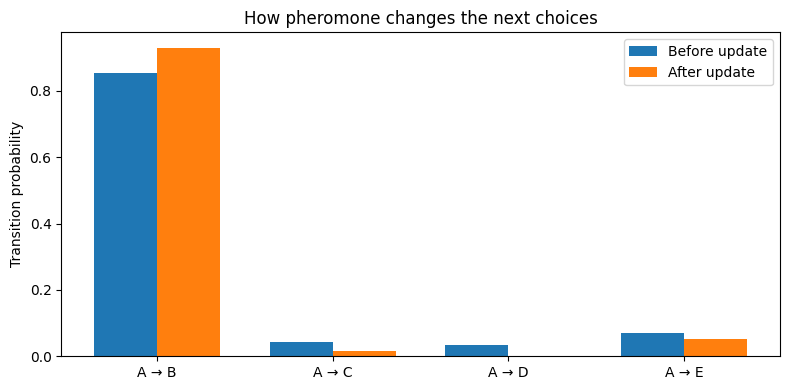

In [16]:
before = transition_probabilities(0, [1, 2, 3, 4], pheromone)
after = transition_probabilities(0, [1, 2, 3, 4], updated_pheromone)
for city, old, new in zip(cities[1:], before, after):
    print(f"A → {city}: {old:.6f} → {new:.6f}")

positions = np.arange(4)
plt.figure(figsize=(8, 4))
plt.bar(positions - 0.18, before, width=0.36, label="Before update")
plt.bar(positions + 0.18, after, width=0.36, label="After update")
plt.xticks(positions, [f"A → {city}" for city in cities[1:]])
plt.ylabel("Transition probability")
plt.title("How pheromone changes the next choices")
plt.legend()
plt.tight_layout()
plt.show()

## 17. Report the best tour in this iteration
This is the best of the three given tours; a single iteration does not establish the globally shortest tour.

In [17]:
best_ant = np.argmin(lengths)
print("Best tour: " + " → ".join(cities[tours[best_ant]]))
print(f"Tour length: {lengths[best_ant]:g}")

Best tour: A → B → E → D → C → A
Tour length: 27


### Expected results
- Tour lengths: **27, 28, 28**.
- Per-ant deposits: **3.703704, 3.571429, 3.571429**.
- Updated AB and CD: **11.346561** each.
- Updated BE and AC: **4.203704** each.
- Updated AE and BC: **7.642857** each.
- Updated DE: **11.346561**.
- Unused AD, BD, CE: **0.5** each.

To continue ACO, use the updated pheromone to sample three new tours, then repeat the length, reward, evaporation, and update steps.

# Parameter experiments: what changes the result?
The worked example above uses fixed tours. To judge parameters, we now **sample new tours at every iteration** using the same distance matrix and update rule.

We change **one parameter at a time**, keep the others at their baseline, and use the same **30 random seeds** for every setting. These are observations for this small problem, not universal rankings.

## 18. Verify the true optimum
With only five cities, we can enumerate every tour while fixing A as the start. This gives an independent benchmark for evaluating ACO. ACO itself does not use this answer to select moves.

In [18]:
from itertools import permutations
import pandas as pd

def tour_length(tour):
    return float(distance[tour[:-1], tour[1:]].sum())

all_tours = [[0, *order, 0] for order in permutations(range(1, len(cities)))]
exact_tour = min(all_tours, key=tour_length)
exact_length = tour_length(exact_tour)
print("Exact shortest tour:", " → ".join(cities[exact_tour]))
print("Exact shortest length:", exact_length)

Exact shortest tour: A → B → E → D → C → A
Exact shortest length: 27.0


## 19. Generate one tour probabilistically
At each move, sample from the unvisited cities using the normalized pheromone × desirability weights. The start cities cycle through A, B, C, so three ants match the notes. Additional ants repeat those starts.

Logarithms compute the same probabilities while avoiding very large or tiny intermediate powers.

In [19]:
def sample_tour(start, tau, alpha, beta, rng):
    tour = [start]
    unvisited = [i for i in range(len(cities)) if i != start]
    while unvisited:
        current = tour[-1]
        log_weights = alpha * np.log(tau[current, unvisited]) + beta * np.log(eta[current, unvisited])
        weights = np.exp(log_weights - log_weights.max())
        probabilities = weights / weights.sum()
        next_city = int(rng.choice(unvisited, p=probabilities))
        tour.append(next_city)
        unvisited.remove(next_city)
    return tour + [start]

## 20. Run complete ACO iterations
Every ant in an iteration uses the same pheromone. Then all deposits are combined and evaporation is applied once.

We record the best length so far and when the known optimum was first discovered. The optimum is used **only for evaluation**, and does not terminate the search. A tiny pheromone floor keeps logarithms valid.

In [20]:
def run_aco(alpha=1, beta=2, rho=0.5, Q=100,
            n_ants=3, n_iterations=20, initial_pheromone=1, seed=0):
    rng = np.random.default_rng(seed)
    tau = np.full_like(distance, float(initial_pheromone))
    np.fill_diagonal(tau, 0)
    best_length = np.inf
    best_tour = None
    history = []
    first_optimal_iteration = np.nan
    first_optimal_evaluation = np.nan
    evaluations = 0

    for iteration in range(1, n_iterations + 1):
        deposits = np.zeros_like(distance)
        for ant in range(n_ants):
            tour = sample_tour(ant % 3, tau, alpha, beta, rng)
            length = tour_length(tour)
            evaluations += 1
            if length < best_length:
                best_length, best_tour = length, tour
            if np.isnan(first_optimal_iteration) and np.isclose(length, exact_length):
                first_optimal_iteration = iteration
                first_optimal_evaluation = evaluations
            for i, j in zip(tour[:-1], tour[1:]):
                deposits[i, j] += Q / length
                deposits[j, i] += Q / length
        tau = np.maximum((1 - rho) * tau + deposits, 1e-12)
        np.fill_diagonal(tau, 0)
        history.append(best_length)

    return dict(best_length=best_length, best_tour=best_tour, history=history,
                first_iteration=first_optimal_iteration,
                first_evaluation=first_optimal_evaluation,
                evaluations=evaluations)

## 21. Define the baseline and changes
Baseline: α=1, β=2, ρ=0.5, Q=100, 3 ants, 20 iterations, initial pheromone=1.

We test low and high values, including α=0 and β=0 to remove each influence. Changing ant count or iteration count also changes the computation budget. Q and initial pheromone interact: their **relative scale** affects reinforcement.

In [21]:
baseline = dict(alpha=1, beta=2, rho=0.5, Q=100,
                n_ants=3, n_iterations=20, initial_pheromone=1)
parameter_values = {
    "alpha": [0, 0.5, 3, 5],
    "beta": [0, 1, 5, 10],
    "rho": [0, 0.1, 0.9],
    "Q": [1, 10, 1000],
    "n_ants": [1, 10],
    "n_iterations": [1, 5, 100],
    "initial_pheromone": [0.1, 10]
}
seeds = range(30)
experiments = [("baseline", "—", baseline.copy())]
for parameter, values in parameter_values.items():
    for value in values:
        settings = {**baseline, parameter: value}
        experiments.append((parameter, value, settings))
print(f"{len(experiments)} settings × {len(seeds)} seeds")

22 settings × 30 seeds


## 22. Run each experiment and collect evidence
- **Mean final length / worst length:** smaller is better.
- **Optimal runs / success %:** how often the exact optimum is found.
- **Mean first-hit iteration and evaluations:** speed of finding the optimum, averaged **only over successful runs**. Read alongside success rate; failures are excluded.
- **Tours per run:** computation budget, not measured wall-clock time.
- **SD:** variation in the final best length across seeds.

In [22]:
records = []
histories = {}
for parameter, value, settings in experiments:
    runs = [run_aco(**settings, seed=seed) for seed in seeds]
    final_lengths = np.array([run["best_length"] for run in runs])
    successes = [run for run in runs if np.isclose(run["best_length"], exact_length)]
    label = "Baseline" if parameter == "baseline" else f"{parameter}={value}"
    histories[label] = np.array([run["history"] for run in runs])
    records.append({
        "Parameter": parameter, "Value": value,
        "Mean final length": final_lengths.mean(),
        "Worst length": final_lengths.max(),
        "SD": final_lengths.std(ddof=1),
        "Optimal runs": len(successes),
        "Success %": 100 * len(successes) / len(runs),
        "First-hit iteration": np.mean([r["first_iteration"] for r in successes]) if successes else np.nan,
        "First-hit tours": np.mean([r["first_evaluation"] for r in successes]) if successes else np.nan,
        "Tours per run": runs[0]["evaluations"]
    })
results = pd.DataFrame(records)
print("Experiments complete.")

Experiments complete.


## 23. Final comparison table with interpretation
The first sentence in each interpretation describes the **observed change relative to baseline**. The second explains the mechanism. A tie is reported as a tie; a five-city problem can be too easy to separate settings.

A smaller mean length is better. Differences from only 30 seeds are descriptive, not proof that a setting will always perform better.

In [23]:
mechanisms = {
    "alpha": "Larger α strengthens pheromone feedback; α=0 removes learned trail influence. Excessive feedback can lock in an early tour.",
    "beta": "Larger β favors shorter individual edges; β=0 removes distance guidance. Local edge preference need not produce the best whole tour.",
    "rho": "Larger ρ forgets old trails faster; ρ=0 retains all old pheromone. Fast forgetting can also reinforce recent choices too strongly.",
    "Q": "Larger Q strengthens deposits relative to initial trails, especially early on. Multiplying all pheromones equally would not change probabilities.",
    "n_ants": "More ants explore more tours before each update, but also use more evaluations per iteration.",
    "n_iterations": "More iterations provide more search opportunities and cost more evaluations. The stored best cannot worsen within one run.",
    "initial_pheromone": "Larger initial trails reduce the early impact of a fixed deposit; equal initial trails still cancel out in first-move probabilities."
}
reference = results.iloc[0]
interpretations = []
for _, row in results.iterrows():
    if row["Parameter"] == "baseline":
        interpretations.append("Reference setting for all comparisons.")
        continue
    delta = row["Mean final length"] - reference["Mean final length"]
    success_delta = row["Success %"] - reference["Success %"]
    if np.isclose(delta, 0) and np.isclose(success_delta, 0):
        observed = "Tied with baseline in mean final length and success rate."
    else:
        observed = f"Mean length change {delta:+.2f}; success change {success_delta:+.1f} percentage points."
    interpretations.append(observed + " " + mechanisms[row["Parameter"]])
results["Interpretation"] = interpretations
results["Mean length change"] = results["Mean final length"] - reference["Mean final length"]
comparison = results[["Parameter", "Value", "Mean final length", "Mean length change", "Worst length", "SD",
                      "Optimal runs", "Success %", "First-hit iteration", "First-hit tours", "Tours per run", "Interpretation"]]
with pd.option_context("display.max_colwidth", 160, "display.max_rows", None, "display.max_columns", None):
    display(comparison.round(3))

,Parameter,Value,Mean final length,Mean length change,Worst length,SD,Optimal runs,Success %,First-hit iteration,First-hit tours,Tours per run,Interpretation
0,baseline,—,27.000,0.000,27.0,0.000,30,100.000,2.100,4.967,60,Reference setting for all comparisons.
1,alpha,0,27.000,0.000,27.0,0.000,30,100.000,1.533,3.133,60,Tied with baseline in mean final length and success rate. Larger α strengthens pheromone feedback; α=0 removes learned trail influence. Excessive feedback c...
2,alpha,0.5,27.000,0.000,27.0,0.000,30,100.000,1.800,4.067,60,Tied with baseline in mean final length and success rate. Larger α strengthens pheromone feedback; α=0 removes learned trail influence. Excessive feedback c...
3,alpha,3,27.267,0.267,29.0,0.521,23,76.667,1.217,2.261,60,Mean length change +0.27; success change -23.3 percentage points. Larger α strengthens pheromone feedback; α=0 removes learned trail influence. Excessive fe...
4,alpha,5,27.533,0.533,30.0,0.900,21,70.000,1.143,2.095,60,Mean length change +0.53; success change -30.0 percentage points. Larger α strengthens pheromone feedback; α=0 removes learned trail influence. Excessive fe...
5,beta,0,27.667,0.667,35.0,1.729,24,80.000,5.000,13.833,60,Mean length change +0.67; success change -20.0 percentage points. Larger β favors shorter individual edges; β=0 removes distance guidance. Local edge prefer...
6,beta,1,27.133,0.133,30.0,0.571,28,93.333,3.179,8.429,60,Mean length change +0.13; success change -6.7 percentage points. Larger β favors shorter individual edges; β=0 removes distance guidance. Local edge prefere...
7,beta,5,27.000,0.000,27.0,0.000,30,100.000,1.133,1.533,60,Tied with baseline in mean final length and success rate. Larger β favors shorter individual edges; β=0 removes distance guidance. Local edge preference nee...
8,beta,10,27.000,0.000,27.0,0.000,30,100.000,1.033,1.100,60,Tied with baseline in mean final length and success rate. Larger β favors shorter individual edges; β=0 removes distance guidance. Local edge preference nee...
9,rho,0,27.000,0.000,27.0,0.000,30,100.000,2.033,4.700,60,Tied with baseline in mean final length and success rate. Larger ρ forgets old trails faster; ρ=0 retains all old pheromone. Fast forgetting can also reinfo...


## 24. Compare how quickly settings improve
Each line is the mean **best-so-far length** across 30 seeds. Lower curves indicate better solutions by that point. The x-axis counts iterations, so ant-count comparisons have different evaluation budgets.

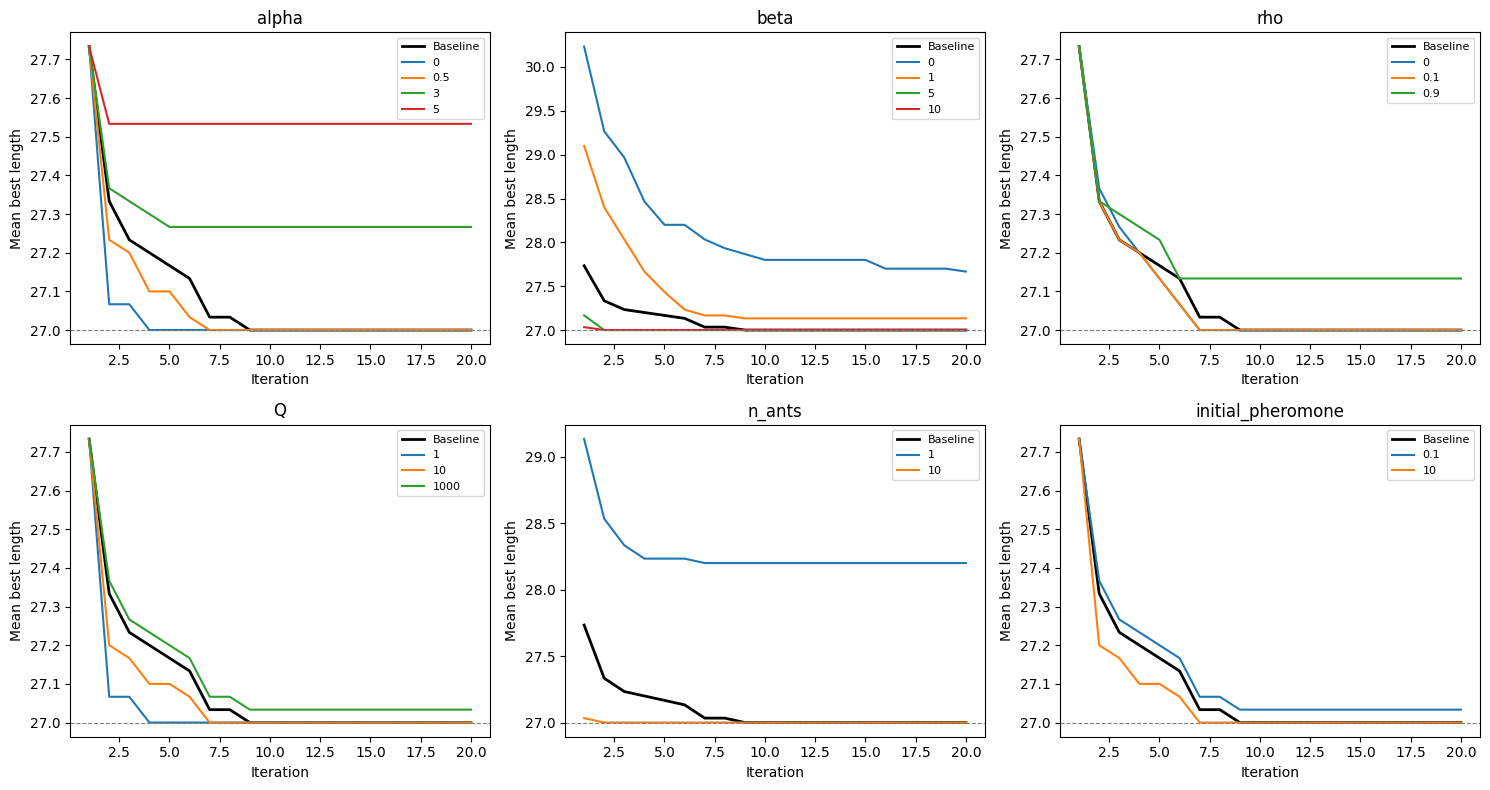

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, parameter in zip(axes.flat, ["alpha", "beta", "rho", "Q", "n_ants", "initial_pheromone"]):
    ax.plot(range(1, 21), histories["Baseline"].mean(axis=0), color="black", linewidth=2, label="Baseline")
    for value in parameter_values[parameter]:
        history = histories[f"{parameter}={value}"]
        ax.plot(range(1, history.shape[1] + 1), history.mean(axis=0), label=str(value))
    ax.axhline(exact_length, color="gray", linestyle="--", linewidth=0.8)
    ax.set(title=parameter, xlabel="Iteration", ylabel="Mean best length")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 25. Read the main findings for this run
This cell creates a short evidence-based summary directly from the table. Rerun after editing settings to refresh it.

In [25]:
print(f"Verified optimum: {exact_length:g}")
print(f"Baseline: mean length {reference['Mean final length']:.3f}, success {reference['Success %']:.1f}%.")
for parameter in parameter_values:
    subset = results[results["Parameter"] == parameter]
    print(f"{parameter}: mean lengths {subset['Mean final length'].min():.3f}–{subset['Mean final length'].max():.3f}; "
          f"success {subset['Success %'].min():.1f}%–{subset['Success %'].max():.1f}%.")
print("Interpret ties using first-hit effort and search budget; do not invent a quality improvement when final results match.")

Verified optimum: 27
Baseline: mean length 27.000, success 100.0%.
alpha: mean lengths 27.000–27.533; success 70.0%–100.0%.
beta: mean lengths 27.000–27.667; success 80.0%–100.0%.
rho: mean lengths 27.000–27.133; success 90.0%–100.0%.
Q: mean lengths 27.000–27.033; success 96.7%–100.0%.
n_ants: mean lengths 27.000–28.200; success 56.7%–100.0%.
n_iterations: mean lengths 27.000–27.733; success 60.0%–100.0%.
initial_pheromone: mean lengths 27.000–27.033; success 96.7%–100.0%.
Interpret ties using first-hit effort and search budget; do not invent a quality improvement when final results match.
